In [1]:
# %pip install torch torchvision pytorchvideo opencv-python pandas numpy matplotlib scikit-learn

In [2]:
from pathlib import Path
import os
import sys
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, precision_score, recall_score

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

# check the root for the path
MATERIALS_DIR = Path("/projectnb/cs541/materials")

ROOT = next(
    (
        p for p in MATERIALS_DIR.iterdir()
        if p.is_dir()
        and (p / "starter" / "cpr_data.py").is_file()
        and (p / "train.csv").is_file()
    ),
    None
)

if ROOT is None:
    raise FileNotFoundError

WORK_DIR = Path("/projectnb/cs541/students/liting99")

sys.path.insert(0, str(ROOT / "starter"))
os.environ["CPR_DATA"] = str(ROOT)

import cpr_data
cpr_data.LOCAL_ROOT = str(ROOT)

OUTPUT_DIR = WORK_DIR / "outputs" / "x3d_L"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset:", ROOT)
print("Personal directory:", WORK_DIR)
print("Outputs:", OUTPUT_DIR)
print("Device:", DEVICE)

Dataset: /projectnb/cs541/materials/cpr_challenge
Personal directory: /projectnb/cs541/students/liting99
Outputs: /projectnb/cs541/students/liting99/outputs/x3d_L
Device: cuda


In [3]:
train = pd.read_csv(cpr_data.data_file('train.csv'))
sample = pd.read_csv(cpr_data.data_file('sample_submission.csv'))
labels = list(sample.columns[1:])
NUM_CLASSES = len(labels)
assert NUM_CLASSES == 13
assert set(labels).issubset(train.columns)

print('Training videos:', len(train))
print('Test videos:', len(sample))
print('Error labels:', labels)
display(train[['video_id', 'class_name', *labels]].head(3))

Training videos: 1008
Test videos: 4320
Error labels: ['e01_overlap_hands', 'e02_clenching_hands', 'e03_single_hand', 'e04_bending_arms', 'e05_tilting_arms', 'e06_jump_pressing', 'e07_squatting', 'e08_standing', 'e09_wrong_position', 'e10_insufficient_pressing', 'e11_slow_frequency', 'e12_excessive_pressing', 'e13_random_position_pressing']


,video_id,class_name,e01_overlap_hands,e02_clenching_hands,e03_single_hand,e04_bending_arms,e05_tilting_arms,e06_jump_pressing,e07_squatting,e08_standing,e09_wrong_position,e10_insufficient_pressing,e11_slow_frequency,e12_excessive_pressing,e13_random_position_pressing
0,CPR_Dataset_S0__C00_S0__r00__ch0,Correct,0,0,0,0,0,0,0,0,0,0,0,0,0
1,CPR_Dataset_S0__C00_S0__r00__ch1,Correct,0,0,0,0,0,0,0,0,0,0,0,0,0
2,CPR_Dataset_S0__C00_S0__r00__ch2,Correct,0,0,0,0,0,0,0,0,0,0,0,0,0


Train & Validation Split of 'take' recordings. MAke sure validation measures performance on different CPR attempts, not just different views of attempts the model has already seen.

In [4]:
take_table = train.groupby('take', as_index=False).agg(class_id=('class_id', 'first'))
class_take_counts = take_table['class_id'].value_counts()
print('Independent takes per class:')
display(class_take_counts.sort_index().rename('takes').to_frame())


train_takes, val_takes = train_test_split(
    take_table['take'], test_size=0.20, random_state=SEED,
    stratify=take_table['class_id']
)
train_split = train[train['take'].isin(train_takes)].reset_index(drop=True)
val_split = train[train['take'].isin(val_takes)].reset_index(drop=True)
print('Training videos:', len(train_split), 
      '\nValidation videos:', len(val_split))
display(pd.DataFrame({
    'train': train_split['class_name'].value_counts(),
    'validation': val_split['class_name'].value_counts()
}).fillna(0).astype(int))
print('View distribution:')
display(pd.DataFrame({
    'train': train_split['view'].value_counts(),
    'validation': val_split['view'].value_counts()
}).fillna(0).astype(int))

Independent takes per class:


,takes
class_id,
0,24
1,24
2,24
3,24
4,24
5,24
6,24
7,24
8,24


Training videos: 804 
Validation videos: 204


,train,validation
class_name,,
Bending Arms,57,15
Clenching Hands,57,15
Correct,57,15
Excessive Pressing,57,15
Insufficient Pressing,57,15
Jump Pressing,57,15
Overlap Hands,57,15
Random Position Pressing,57,15
Single Hand,57,15


View distribution:


,train,validation
view,,
ch0,268,68
ch1,268,68
ch2,268,68


### Read an video as a PyTorch tensor

In [5]:

import cv2
NUM_FRAMES = 16
FRAME_STRIDE = 5
SIZE = 320
FPS = 25

# OVERLAP = 0.5  # 50% overlap

# WINDOW_FRAMES = NUM_FRAMES * FRAME_STRIDE
# WINDOW_STEP = int(WINDOW_FRAMES * (1 - OVERLAP))

WINDOW_FRAMES = NUM_FRAMES * FRAME_STRIDE
WINDOW_STEP = WINDOW_FRAMES  # No overlap

def load_video_windows(video_path):
    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        raise ValueError(f"Cannot open video: {video_path}")

    sampled = []
    frame_idx = 0

    while True:
        success, frame = cap.read()
        if not success:
            break

        if frame_idx % FRAME_STRIDE == 0:
            frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            frame = cv2.resize(frame, (SIZE, SIZE))
            sampled.append(frame)

        frame_idx += 1

    cap.release()

    if not sampled:
        raise ValueError(f"No frames: {video_path}")

    windows = []
    

    for start in range(0, len(sampled), NUM_FRAMES):
        clip = sampled[start:start + NUM_FRAMES]

        # Pad the last incomplete window
        if len(clip) < NUM_FRAMES:
            clip += [clip[-1]] * (NUM_FRAMES - len(clip))

        windows.append(np.stack(clip))

    return windows


row = train.iloc[0]
video_path = cpr_data.video_file(row.video_id, "train")

windows = load_video_windows(video_path)
frames = windows[0]

print("Video:", row.video_id)
print("Number of windows:", len(windows))
print("Window shape:", windows[0].shape)
print("Window duration:", WINDOW_FRAMES / FPS, "seconds")


Video: CPR_Dataset_S0__C00_S0__r00__ch0
Number of windows: 4
Window shape: (16, 320, 320, 3)
Window duration: 3.2 seconds


### Convert input to match X3D-L
X3D-L's expected input [B,C,T,H,W], so need to reorder our [T,H,W,C] to be [C,T,H,W], and also apply normalization with the X3D recipe's RGB mean 0.45 and standard deviation 0.225

In [6]:
def preprocess_video(frames, num_frames=NUM_FRAMES):
    if len(frames) == 0:
        raise ValueError('No frames')
    frames = frames[:num_frames]
    if len(frames) < num_frames:
        frames = np.concatenate(
            [frames, np.repeat(frames[-1:], num_frames - len(frames), axis=0)],
            axis=0
        )

    video = torch.from_numpy(np.ascontiguousarray(frames)).float() / 255.0
    video = video.permute(3, 0, 1, 2)      # [C,T,H,W]
    video = (video - 0.45) / 0.225        # X3D mean/std
    return video

x = preprocess_video(frames).unsqueeze(0).to(DEVICE)
print('Input shade:', tuple(x.shape))

Input shade: (1, 3, 16, 320, 320)


### Load pretrained X3D-L
Replace its original network 400 classification projection with a 13 output FC layer for multilabel CPR errors. 

In [7]:
model = torch.hub.load(
    'facebookresearch/pytorchvideo', 'x3d_l', pretrained=True
)

head = model.blocks[-1]

d = head.proj.in_features
head.proj = nn.Linear(d, NUM_CLASSES)       # REPLACE to be our own class size
head.activation = nn.Identity()            # keep raw logits

model = model.to(DEVICE)
print('New classifier:', model.blocks[-1].proj)

Using cache found in /usr4/ds340/liting99/.cache/torch/hub/facebookresearch_pytorchvideo_main
/projectnb/cs541/students/liting99/.venv312/lib64/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/projectnb/cs541/students/liting99/.venv312/lib64/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


New classifier: Linear(in_features=2048, out_features=13, bias=True)


Forward pass after replacement

In [8]:
model.eval()
with torch.no_grad():
    logits = model(x)                       # forward only

print("Output shape:", logits.shape)

Output shape: torch.Size([1, 13])


### Fine-tune the last two X3D-L backbone blocks and the new FC layer
Freeze the earlier backbone blocks and cache their activations once. Only the last two backbone blocks and new 13-output FC projection receive parameter updates.

In [9]:
class CPRDataset(Dataset):
    def __init__(self, table):
        self.table = table.reset_index(drop=True)

    def __len__(self):
        return len(self.table)

    def __getitem__(self, idx):
        row = self.table.iloc[idx]
        # frames = cpr_data.load_video(
        #     cpr_data.video_file(row.video_id, 'train'),
        #     stride=FRAME_STRIDE,
        #     max_frames=NUM_FRAMES,
        #     size=(SIZE, SIZE),
        # )
        windows = load_video_windows(
            cpr_data.video_file(row.video_id, "train")
        )
        videos = torch.stack([
            preprocess_video(window)
            for window in windows
        ])

        target = torch.tensor(
            row[labels].to_numpy(dtype=np.float32)
        )
        # video = preprocess_video(frames)  
        # target = torch.tensor(row[labels].to_numpy(dtype=np.float32))
        return videos, target           # [3,T,H,W], [13]

BATCH_SIZE = 1 # one video per batch 

def collate_videos(batch):
    return batch[0]

train_loader = DataLoader(
    CPRDataset(train_split),
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_videos,
    num_workers=0
)
val_loader = DataLoader(
    CPRDataset(val_split),
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_videos,
    num_workers=0
)

batch_video, batch_targets = next(iter(train_loader))
print('Video batch:', tuple(batch_video.shape))
print('Target batch:', tuple(batch_targets.shape))

Video batch: (11, 3, 16, 320, 320)
Target batch: (13,)


Freeze all pretrained weights, train the last two backbone blocks and the new FC layer.

In [10]:
# freeze all level first anad then unfreeze only the new fc layer
for parameter in model.parameters():
    parameter.requires_grad = False

for block in (model.blocks[-3], model.blocks[-2]):
    for parameter in block.parameters():
        parameter.requires_grad = True

for parameter in model.blocks[-1].proj.parameters():
    parameter.requires_grad = True

frozen_prefix = nn.Sequential(*list(model.blocks)[:-3]).to(DEVICE)
trainable_suffix = nn.Sequential(*list(model.blocks)[-3:]).to(DEVICE)

# trainable = [
#     (name, tuple(p.shape)) 
#     for name, p in model.named_parameters() 
#     if p.requires_grad]
# print('Trainable tensors:', trainable)

for index, block in enumerate(model.blocks):
    count = sum(p.numel() for p in block.parameters() if p.requires_grad)
    print(f'Block {index}: trainable parameters = {count:,}')

criterion = nn.BCEWithLogitsLoss() # loss function with binary cross entropy
optimizer = torch.optim.AdamW(
    [
        {
            'params': list(model.blocks[-3].parameters())
                      + list(model.blocks[-2].parameters()),
            'lr': 1e-4,
        },
        {
            'params': model.blocks[-1].proj.parameters(),
            'lr': 1e-3,
        },
    ],
    weight_decay=1e-4,
)

optimized_ids = {id(p) for group in optimizer.param_groups for p in group['params']}
trainable_ids = {id(p) for p in model.parameters() if p.requires_grad}

THRESHOLD = 0.5
CHECKPOINT = (OUTPUT_DIR / "x3d_l_nonoverlap_best.pt")


Block 0: trainable parameters = 0
Block 1: trainable parameters = 0
Block 2: trainable parameters = 0
Block 3: trainable parameters = 1,296,304
Block 4: trainable parameters = 2,897,200
Block 5: trainable parameters = 26,637


Cache frozen features for every window

In [11]:
import hashlib
import json

FEATURE_BATCH_SIZE = 2

# saving the output of the frozen layers to increase the speed in every training epoch
def feature_cache_path(table, split_name):
    settings = {
        "version": "x3d_l_nonoverlap_v1",
        "split": split_name,
        "video_ids": table["video_id"].astype(str).tolist(),
        "labels": labels,
        "num_frames": NUM_FRAMES,
        "frame_stride": FRAME_STRIDE,
        "window_step": WINDOW_STEP,
        "size": SIZE,
        "backbone": "x3d_l",
    }
    signature = hashlib.sha256(json.dumps(settings, sort_keys=True).encode()).hexdigest()[:16]
    return OUTPUT_DIR / f"{split_name}_{signature}.pt"

@torch.no_grad()
def get_or_create_features(table, split_name):
    cache_path = feature_cache_path(table, split_name)
    if cache_path.exists():
        cached = torch.load(cache_path, map_location='cpu', weights_only=True)
        return cached['features'], cached['targets']
        
    frozen_prefix.eval()
    features_all, targets_all = [], []
    dataset = CPRDataset(table)
    
    for i in range(len(dataset)):
        windows, target = dataset[i]
        video_features = []

        for start in range(0, len(windows), FEATURE_BATCH_SIZE):
            batch = windows[
                start:start + FEATURE_BATCH_SIZE
            ].to(DEVICE)

            features = frozen_prefix(batch)
            video_features.append(features.cpu())

        features_all.append(torch.cat(video_features))
        targets_all.append(target)

        if (i + 1) % 10 == 0 or i + 1 == len(dataset):
            print(
                f"{split_name}: {i + 1}/{len(dataset)} "
                "videos cached"
            )
    targets_all = torch.stack(targets_all)

    torch.save({
        "features": features_all,
        "targets": targets_all,
    }, cache_path)

    return features_all, targets_all

train_features, train_targets = get_or_create_features(
    train_split, "train"
)

val_features, val_targets = get_or_create_features(
    val_split, "val"
)

### Evaluate with macro-F1

Update validation to aggregate window predictions；
average the logits across windows before computing the video-level BCE loss and predictions.

Apply sigmoid to obtain 13 scores in [0,1], then threshold each score to produce binary predictions.

In [12]:
def video_logits(features, chunk_size=FEATURE_BATCH_SIZE):
    outputs = []

    for start in range(0, len(features), chunk_size):
        batch = features[
            start:start + chunk_size
        ].to(DEVICE)

        outputs.append(trainable_suffix(batch))

    return torch.cat(outputs).mean(dim=0, keepdim=True)


@torch.no_grad()
def evaluate(model, features_list, targets_list,
             threshold=THRESHOLD):
    model.eval()

    all_probs = []
    all_targets = []
    total_loss = 0.0

    for features, target in zip(features_list, targets_list):
        target = target.unsqueeze(0).to(DEVICE)

        logits = video_logits(features)
        loss = criterion(logits, target)

        total_loss += loss.item()
        all_probs.append(torch.sigmoid(logits).cpu())
        all_targets.append(target.cpu())

    probs = torch.cat(all_probs).numpy()
    targets = torch.cat(all_targets).numpy()
    predictions = (probs >= threshold).astype(int)

    return {
        "loss": total_loss / len(features_list),
        "macro_f1": f1_score(
            targets, predictions,
            average="macro", zero_division=0
        ),
        "precision_macro": precision_score(
            targets, predictions,
            average="macro", zero_division=0
        ),
        "recall_macro": recall_score(
            targets, predictions,
            average="macro", zero_division=0
        ),
        "probs": probs,
        "targets": targets,
        "predictions": predictions,
    }

def per_error_report(metrics):
    y_true = metrics['targets']
    y_pred = metrics['predictions']

    return pd.DataFrame({
        'error': labels,
        'validation_positives': y_true.sum(axis=0),
        'predicted_positives': y_pred.sum(axis=0),
        'precision': precision_score(
            y_true, y_pred, average=None, zero_division=0
        ),
        'recall': recall_score(
            y_true, y_pred, average=None, zero_division=0
        ),
        'f1': f1_score(
            y_true, y_pred, average=None, zero_division=0
        ),
    })

Train the FC layer for a few epochs

In [13]:
EPOCHS = 20
PATIENCE = 5
epochs_without_improvement = 0


history = []
best_f1 = -1.0

for epoch in range(1, EPOCHS + 1):
    start = time.time()
    model.eval()  # keep frozen prefix and head BatchNorm/dropout behavior fixed
    model.blocks[-3].train()
    model.blocks[-2].train()
    model.blocks[-1].proj.train()
    running_loss = 0.0

    indices = torch.randperm(len(train_features)).tolist()

    for idx in indices:
            features = train_features[idx]
            target = train_targets[idx].unsqueeze(0).to(DEVICE)

            optimizer.zero_grad(set_to_none=True)

            logits = video_logits(features)
            loss = criterion(logits, target)

            loss.backward()
            optimizer.step()

            running_loss += loss.item()

    train_loss = running_loss / len(train_features)
    valid = evaluate(model, val_features, val_targets)
    history.append({
        'epoch': epoch,
        'train_loss': train_loss,
        'val_loss': valid['loss'],
        'val_macro_f1': valid['macro_f1'],
        'val_macro_precision': valid['precision_macro'],
        'val_macro_recall': valid['recall_macro'],
    })

    # if valid['macro_f1'] > best_f1:
    #     best_f1 = valid['macro_f1']
    #     torch.save({
    #         'model_state_dict': model.state_dict(),
    #         'labels': labels,
    #         'epoch': epoch,
    #         'threshold': THRESHOLD,
    #         'val_macro_f1': best_f1,
    #         'strategy': 'last2_backbone_plus_fc_cached_prefix',
    #     }, CHECKPOINT)

    # add early stopping 


    if valid['macro_f1'] > best_f1:
        best_f1 = valid['macro_f1']
        epochs_without_improvement = 0

        torch.save({
            'model_state_dict': model.state_dict(),
            'labels': labels,
            'epoch': epoch,
            'threshold': THRESHOLD,
            'val_macro_f1': best_f1,
        }, CHECKPOINT)

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping at epoch {epoch}")
        break

    print(
        f"Epoch {epoch}: "
        f"train BCE={train_loss:.4f}, "
        f"val BCE={valid['loss']:.4f}, "
        f"val macro-F1={valid['macro_f1']:.4f}, "
    )


history_df = pd.DataFrame(history)
display(history_df)

Epoch 1: train BCE=0.1510, val BCE=0.1104, val macro-F1=0.6084, 
Epoch 2: train BCE=0.0396, val BCE=0.0308, val macro-F1=0.9073, 
Epoch 3: train BCE=0.0209, val BCE=0.0308, val macro-F1=0.9030, 
Epoch 4: train BCE=0.0124, val BCE=0.0280, val macro-F1=0.9166, 
Epoch 5: train BCE=0.0083, val BCE=0.0468, val macro-F1=0.9375, 
Epoch 6: train BCE=0.0070, val BCE=0.0208, val macro-F1=0.9402, 
Epoch 7: train BCE=0.0124, val BCE=0.0311, val macro-F1=0.8880, 
Epoch 8: train BCE=0.0104, val BCE=0.0208, val macro-F1=0.9575, 
Epoch 9: train BCE=0.0046, val BCE=0.0331, val macro-F1=0.9178, 
Epoch 10: train BCE=0.0138, val BCE=0.4057, val macro-F1=0.8512, 
Epoch 11: train BCE=0.0011, val BCE=0.0552, val macro-F1=0.9432, 
Epoch 12: train BCE=0.0001, val BCE=0.1670, val macro-F1=0.8984, 
Early stopping at epoch 13


,epoch,train_loss,val_loss,val_macro_f1,val_macro_precision,val_macro_recall
0,1,0.150988,0.110430,0.608442,0.615392,0.629487
1,2,0.039613,0.030795,0.907309,0.975379,0.867949
2,3,0.020901,0.030788,0.902978,0.950814,0.885897
3,4,0.012397,0.028021,0.916598,0.985033,0.902564
4,5,0.008337,0.046801,0.937479,0.941922,0.947436
5,6,0.007000,0.020776,0.940180,0.953654,0.948718
6,7,0.012371,0.031133,0.887989,0.941782,0.871795
7,8,0.010377,0.020765,0.957453,0.980769,0.948718
8,9,0.004579,0.033097,0.917778,0.960108,0.902564
9,10,0.013787,0.405694,0.851211,0.875824,0.846154


Reload the best epoch, calculate validation metrics again, and got the F1 scores

Best epoch: 8
Validation macro-F1: 0.9575
Validation macro-precision: 0.9808
Validation macro-recall: 0.9487


,error,validation_positives,predicted_positives,precision,recall,f1
0,e01_overlap_hands,15.0,15,1.00,1.000000,1.000000
1,e02_clenching_hands,15.0,15,1.00,1.000000,1.000000
2,e03_single_hand,15.0,15,1.00,1.000000,1.000000
3,e04_bending_arms,15.0,15,1.00,1.000000,1.000000
4,e05_tilting_arms,15.0,13,1.00,0.866667,0.928571
5,e06_jump_pressing,15.0,15,1.00,1.000000,1.000000
6,e07_squatting,15.0,14,1.00,0.933333,0.965517
7,e08_standing,15.0,15,1.00,1.000000,1.000000
8,e09_wrong_position,12.0,12,1.00,1.000000,1.000000
9,e10_insufficient_pressing,15.0,8,1.00,0.533333,0.695652


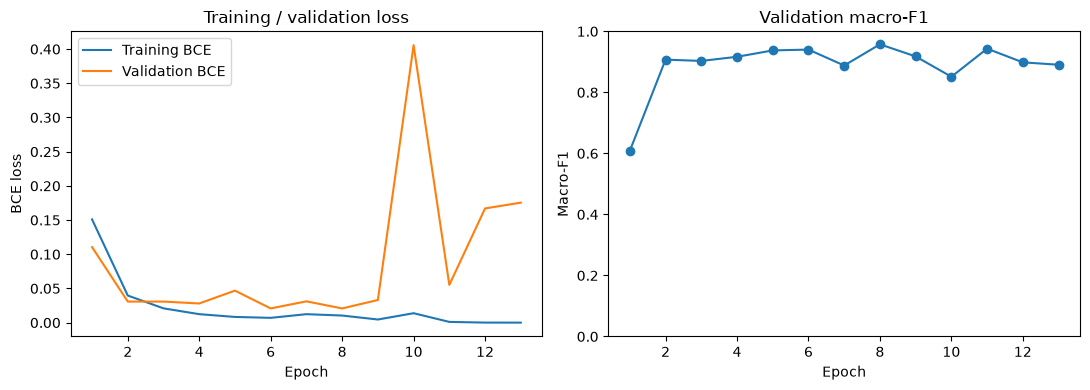

In [14]:
checkpoint = torch.load(
    CHECKPOINT,
    map_location=DEVICE,
    weights_only=True
)

model.load_state_dict(checkpoint['model_state_dict'])

# Evaluate using cached validation features
best_metrics = evaluate(
    model,
    val_features,
    val_targets,
    threshold=checkpoint["threshold"]
)

print('Best epoch:', checkpoint['epoch'])
print(f"Validation macro-F1: {best_metrics['macro_f1']:.4f}")
print(f"Validation macro-precision: {best_metrics['precision_macro']:.4f}")
print(f"Validation macro-recall: {best_metrics['recall_macro']:.4f}")

display(per_error_report(best_metrics))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(
    history_df['epoch'],
    history_df['train_loss'],
    label='Training BCE'
)
axes[0].plot(
    history_df['epoch'],
    history_df['val_loss'],
    label='Validation BCE'
)
axes[0].set(
    xlabel='Epoch',
    ylabel='BCE loss',
    title='Training / validation loss'
)
axes[0].legend()

axes[1].plot(
    history_df['epoch'],
    history_df['val_macro_f1'],
    marker='o'
)
axes[1].set(
    xlabel='Epoch',
    ylabel='Macro-F1',
    title='Validation macro-F1',
    ylim=(0, 1)
)

plt.tight_layout()
plt.show()

Load the test dataset

In [15]:
threshold = checkpoint['threshold']

model.eval()

all_predictions = []

with torch.no_grad():
    # Load test video

    for i, video_id in enumerate(sample["video_id"]):
        windows = load_video_windows(
            cpr_data.video_file(video_id, "test")
        )

        logits_all = []

        for start in range(0, len(windows), FEATURE_BATCH_SIZE):
            batch_windows = windows[
                start:start + FEATURE_BATCH_SIZE
            ]

            batch = torch.stack([
                preprocess_video(window)
                for window in batch_windows
            ]).to(DEVICE)

            logits = model(batch)
            logits_all.append(logits.cpu())

        # One prediction per complete video
        video_logits_avg = torch.cat(
            logits_all, dim=0
        ).mean(dim=0)

        probabilities = torch.sigmoid(video_logits_avg)

        prediction = (
            probabilities >= threshold
        ).int().numpy()

        all_predictions.append(prediction)

        if (i + 1) % 25 == 0:
            print(f"Tested {i + 1}/{len(sample)} videos")

all_predictions = np.stack(all_predictions)

print("Test predictions:", all_predictions.shape)

Tested 25/4320 videos
Tested 50/4320 videos
Tested 75/4320 videos
Tested 100/4320 videos
Tested 125/4320 videos
Tested 150/4320 videos
Tested 175/4320 videos
Tested 200/4320 videos
Tested 225/4320 videos
Tested 250/4320 videos
Tested 275/4320 videos
Tested 300/4320 videos
Tested 325/4320 videos
Tested 350/4320 videos
Tested 375/4320 videos
Tested 400/4320 videos
Tested 425/4320 videos
Tested 450/4320 videos
Tested 475/4320 videos
Tested 500/4320 videos
Tested 525/4320 videos
Tested 550/4320 videos
Tested 575/4320 videos
Tested 600/4320 videos
Tested 625/4320 videos
Tested 650/4320 videos
Tested 675/4320 videos
Tested 700/4320 videos
Tested 725/4320 videos
Tested 750/4320 videos
Tested 775/4320 videos
Tested 800/4320 videos
Tested 825/4320 videos
Tested 850/4320 videos
Tested 875/4320 videos
Tested 900/4320 videos
Tested 925/4320 videos
Tested 950/4320 videos
Tested 975/4320 videos
Tested 1000/4320 videos
Tested 1025/4320 videos
Tested 1050/4320 videos
Tested 1075/4320 videos
Tested 110

### Export Submission


In [16]:
submission = sample.copy()
submission[labels] = all_predictions
cpr_data.check_submission(submission, sample)

# Save CSV
submission_path = OUTPUT_DIR / 'submission.csv'
submission.to_csv(submission_path, index=False)

print('Submission saved:', submission_path)
display(submission.head())

Submission saved: /projectnb/cs541/students/liting99/outputs/x3d_L/submission.csv


,video_id,e01_overlap_hands,e02_clenching_hands,e03_single_hand,e04_bending_arms,e05_tilting_arms,e06_jump_pressing,e07_squatting,e08_standing,e09_wrong_position,e10_insufficient_pressing,e11_slow_frequency,e12_excessive_pressing,e13_random_position_pressing
0,000f31ac,0,0,0,0,1,0,0,0,0,0,0,0,0
1,0012a6ff,0,0,1,0,0,0,0,0,0,0,0,0,0
2,002930be,0,0,1,0,0,0,0,0,0,0,0,0,0
3,00293fa6,0,0,0,0,1,0,0,0,0,0,0,0,0
4,002d37f9,0,1,0,0,0,0,0,0,0,0,0,0,0


In [17]:
# Number of predicted errors per test video
error_counts = submission[labels].sum(axis=1)

print('Predicted errors per video:')
print(error_counts.value_counts().sort_index())

print('Total test videos:', len(submission))
print('Videos predicted correct:', (error_counts == 0).sum())
print('Videos with multiple predicted errors:', (error_counts >= 2).sum())

Predicted errors per video:
0     803
1    3402
2     115
Name: count, dtype: int64
Total test videos: 4320
Videos predicted correct: 803
Videos with multiple predicted errors: 115
